# Lab 03 — Attention from scratch

**Book sections:** [2.1 Attention](../../book/docs/chapters/02-transformers/attention.md),
[2.2 Multi-head and cross-attention](../../book/docs/chapters/02-transformers/multi-head.md).

**Goal.** Implement scaled dot-product attention step by step on the running example, inspect every
tensor, verify the $\sqrt{d_k}$ argument, build masks, check permutation equivariance, implement
multi-head and cross-attention, and train an attention layer to solve an associative-recall task so you
can watch a *learned* attention pattern.

**Runtime:** < 1 minute on CPU. **Seed:** 0.

In [1]:
import math

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from vlacourse.attention import MultiHeadAttention, scaled_dot_product_attention
from vlacourse.seed import set_seed

set_seed(0)


def show(A, xlabels, ylabels, title):
    fig, ax = plt.subplots(figsize=(0.45 * len(xlabels) + 2, 0.45 * len(ylabels) + 1))
    im = ax.imshow(A, cmap="viridis", vmin=0)
    ax.set_xticks(range(len(xlabels)), xlabels, rotation=60, ha="right")
    ax.set_yticks(range(len(ylabels)), ylabels)
    ax.set_xlabel("key (read from)"); ax.set_ylabel("query (reads)"); ax.set_title(title)
    fig.colorbar(im); plt.show()

## 1. Step by step
Word-level tokens of the running example's first clause, random embeddings ($d=8$), one head with
$d_k=d_v=4$.

Q (9, 4) K (9, 4) V (9, 4)
scores (9, 9) A (9, 9) Y (9, 4)
row sums of A: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


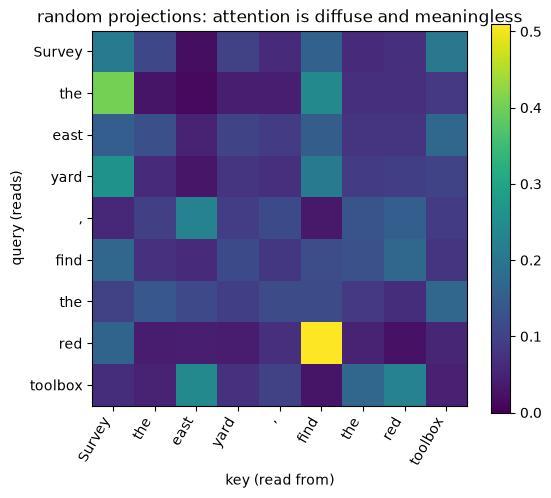

In [2]:
words = ["Survey", "the", "east", "yard", ",", "find", "the", "red", "toolbox"]
T, d, d_k = len(words), 8, 4
X = torch.randn(T, d)                                   # (T, d)
W_Q, W_K, W_V = (torch.randn(d, d_k) / math.sqrt(d) for _ in range(3))

Q = X @ W_Q                                             # (T, d_k): what each token looks for
K = X @ W_K                                             # (T, d_k): what each token offers
V = X @ W_V                                             # (T, d_v): what each token gives
print("Q", tuple(Q.shape), "K", tuple(K.shape), "V", tuple(V.shape))

scores = Q @ K.T                                        # (T, T): entry (i, j) = q_i . k_j
scaled = scores / math.sqrt(d_k)
A = scaled.softmax(dim=-1)                              # (T, T), each row a distribution over keys
Y = A @ V                                               # (T, d_v)
print("scores", tuple(scores.shape), "A", tuple(A.shape), "Y", tuple(Y.shape))
print("row sums of A:", A.sum(-1))
show(A.detach(), words, words, "random projections: attention is diffuse and meaningless")

Each output row is a convex combination of the value rows, so it lies in their convex hull:

In [3]:
i = words.index("toolbox")
print("Y[toolbox] == sum_j A[toolbox, j] V[j]:", torch.allclose(Y[i], (A[i, :, None] * V).sum(0)))

Y[toolbox] == sum_j A[toolbox, j] V[j]: True


## 2. Why divide by $\sqrt{d_k}$?
With unit-variance entries, $\mathrm{Var}(\mathbf q\mathbf k^\top)=d_k$. Empirically:

In [4]:
for dk in [4, 64, 256, 1024]:
    q, k = torch.randn(10000, dk), torch.randn(10000, dk)
    dots = (q * k).sum(-1)
    print(f"d_k={dk:5d}  std(q.k)={dots.std():7.2f}  sqrt(d_k)={math.sqrt(dk):6.2f}  "
          f"std after scaling={(dots / math.sqrt(dk)).std():.2f}")

d_k=    4  std(q.k)=   2.00  sqrt(d_k)=  2.00  std after scaling=1.00
d_k=   64  std(q.k)=   8.10  sqrt(d_k)=  8.00  std after scaling=1.01


d_k=  256  std(q.k)=  15.97  sqrt(d_k)= 16.00  std after scaling=1.00
d_k= 1024  std(q.k)=  32.13  sqrt(d_k)= 32.00  std after scaling=1.00


What large score spread does to the softmax and its gradient: entropy of the attention row (log S is
uniform, 0 is one-hot) and the norm of $\partial(\text{output})/\partial(\text{scores})$.

In [5]:
S, dk = 64, 512
q = torch.randn(1, dk)
Kx, Vx = torch.randn(S, dk), torch.randn(S, dk)
for name, scale in [("unscaled", 1.0), ("scaled by 1/sqrt(d_k)", 1 / math.sqrt(dk))]:
    s = (q @ Kx.T * scale).requires_grad_(True)       # (1, S)
    a = s.softmax(-1)
    out = a @ Vx
    out.sum().backward()
    ent = -(a * a.clamp_min(1e-12).log()).sum().item()
    print(f"{name:22} max weight {a.max().item():.3f}  entropy {ent:.2f} (uniform {math.log(S):.2f})  "
          f"|d out/d scores| = {s.grad.norm().item():.2e}")

unscaled               max weight 1.000  entropy 0.00 (uniform 4.16)  |d out/d scores| = 2.33e-03
scaled by 1/sqrt(d_k)  max weight 0.079  entropy 3.82 (uniform 4.16)  |d out/d scores| = 2.80e+00


Unscaled: one key takes nearly all the weight and the gradient almost vanishes — the softmax is
saturated and cannot learn. Scaled: a soft distribution with useful gradients.

## 3. Masks

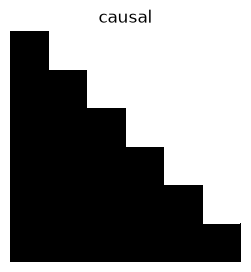

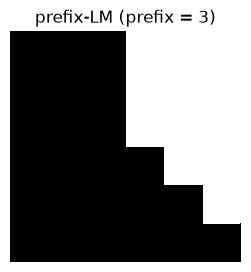

padding mask per sequence:
 tensor([[1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 0, 0]], dtype=torch.int32)
weights on padded keys of sequence 2: 0.0


In [6]:
def show_mask(m, title):
    plt.figure(figsize=(3, 3)); plt.imshow(m, cmap="Greys"); plt.title(title); plt.axis("off"); plt.show()


T = 6
causal = torch.ones(T, T, dtype=torch.bool).tril()
lengths = torch.tensor([6, 4])                          # batch of 2 sequences, the second padded
padding = torch.arange(T)[None, :] < lengths[:, None]   # (B, S): True = real token
prefix = torch.ones(T, T, dtype=torch.bool).tril()
prefix[:3, :3] = True                                   # first 3 tokens (e.g. image + text) bidirectional
show_mask(causal, "causal"); show_mask(prefix, "prefix-LM (prefix = 3)")
print("padding mask per sequence:\n", padding.int())

q = k = v = torch.randn(2, T, 8)
mask = causal[None] & padding[:, None, :]               # (B, T, S): causal AND not padding
out, w = scaled_dot_product_attention(q, k, v, mask)
print("weights on padded keys of sequence 2:", w[1, :, 4:].abs().max().item())

**The all-masked row.** If a query can see no key at all, the softmax computes $0/0$:

In [7]:
s = torch.full((1, 4), float("-inf"))
print(s.softmax(-1))      # NaN, which then poisons everything downstream

tensor([[nan, nan, nan, nan]])


## 4. Permutation equivariance
Without a mask, permuting the tokens permutes the output rows identically. Order is invisible to
attention — hence positional encodings.

In [8]:
mha = MultiHeadAttention(d_model=16, n_heads=4)
x = torch.randn(1, 7, 16)
perm = torch.randperm(7)
with torch.no_grad():
    print("Attn(P x) == P Attn(x):", torch.allclose(mha(x[:, perm]), mha(x)[:, perm], atol=1e-6))

Attn(P x) == P Attn(x): True


## 5. Multi-head attention with the reshape trick
Our hand-written version, checked against `vlacourse.attention.MultiHeadAttention` (same weights) and
PyTorch's fused `scaled_dot_product_attention`.

In [9]:
B, T, d, h = 2, 5, 16, 4
d_h = d // h
x = torch.randn(B, T, d)
ref = MultiHeadAttention(d, h)


def split(t):                                   # (B, T, d) -> (B, h, T, d_h)
    return t.view(B, T, h, d_h).transpose(1, 2)


with torch.no_grad():
    Qh, Kh, Vh = split(ref.q_proj(x)), split(ref.k_proj(x)), split(ref.v_proj(x))
    print("per-head Q:", tuple(Qh.shape))
    A = (Qh @ Kh.transpose(-2, -1) / math.sqrt(d_h)).softmax(-1)      # (B, h, T, T)
    heads = A @ Vh                                                     # (B, h, T, d_h)
    mine = ref.o_proj(heads.transpose(1, 2).reshape(B, T, d))          # (B, T, d)
    fused = ref.o_proj(F.scaled_dot_product_attention(Qh, Kh, Vh).transpose(1, 2).reshape(B, T, d))
    print("mine == vlacourse:", torch.allclose(mine, ref(x), atol=1e-6))
    print("mine == fused SDPA:", torch.allclose(mine, fused, atol=1e-6))
    # Heads write additively: MHA = sum_i head_i W_O^(i)
    W_O = ref.o_proj.weight.T                                          # (d, d), row-vector convention
    per_head = sum(heads[:, i] @ W_O[i * d_h:(i + 1) * d_h] for i in range(h))
    print("sum of per-head contributions == MHA:", torch.allclose(per_head, mine, atol=1e-6))

per-head Q: (2, 4, 5, 4)
mine == vlacourse: True
mine == fused SDPA: True
sum of per-head contributions == MHA: True


## 6. Cross-attention: action queries reading image patches
A VLA action head often has $H_a$ learned queries (one per future step) that read the backbone's
features. Here: 4 queries, 16 "patch" tokens.

In [10]:
H_a, N_p, d = 4, 16, 32
action_queries = nn.Parameter(torch.randn(1, H_a, d))     # learned, shared across examples
patches = torch.randn(3, N_p, d)                          # (B, N_p, d) features from a vision encoder
xattn = MultiHeadAttention(d, n_heads=4)
out = xattn(action_queries.expand(3, -1, -1), context=patches)
print("output", tuple(out.shape), "| attention weights", tuple(xattn.last_weights.shape),
      "= (B, h, H_a, N_p)")

output (3, 4, 32) | attention weights (3, 4, 4, 16) = (B, h, H_a, N_p)


## 7. A learned attention pattern: associative recall

Each example shows 6 (colour → object) pairs and then asks about one colour, e.g.
`red:crate blue:cone green:panel ... ? blue` → answer `cone`. Each pair is one token (colour embedding +
object embedding); the query token is the colour embedding. One attention layer must learn to make the
query's key match the pair with the same colour and copy that pair's object through the values.

In [11]:
from vlacourse.data.instructions import COLORS, OBJECTS

n_col, n_obj, n_pairs = len(COLORS), len(OBJECTS), 6


def make_batch(Bn, gen):
    cols = torch.stack([torch.randperm(n_col, generator=gen)[:n_pairs] for _ in range(Bn)])   # (B, 6)
    objs = torch.randint(0, n_obj, (Bn, n_pairs), generator=gen)                            # (B, 6)
    which = torch.randint(0, n_pairs, (Bn,), generator=gen)
    return cols, objs, cols[torch.arange(Bn), which], objs[torch.arange(Bn), which], which


class Recall(nn.Module):
    def __init__(self, d=32):
        super().__init__()
        self.col, self.obj = nn.Embedding(n_col, d), nn.Embedding(n_obj, d)
        self.attn = MultiHeadAttention(d, n_heads=1)
        self.out = nn.Linear(d, n_obj)

    def forward(self, cols, objs, qcol):
        pairs = self.col(cols) + self.obj(objs)          # (B, 6, d): one token per pair
        query = self.col(qcol)[:, None, :]                # (B, 1, d)
        y = self.attn(query, context=pairs)               # (B, 1, d): cross-attention query -> pairs
        return self.out(y[:, 0])                          # (B, n_obj) logits


set_seed(0)
model = Recall()
opt = torch.optim.Adam(model.parameters(), lr=3e-3)
gen = torch.Generator().manual_seed(0)
for step in range(1500):
    cols, objs, qcol, target, _ = make_batch(256, gen)
    loss = F.cross_entropy(model(cols, objs, qcol), target)
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 500 == 0 or step == 1499:
        print(f"step {step:4d} loss {loss.item():.3f}")

with torch.no_grad():
    cols, objs, qcol, target, which = make_batch(2000, torch.Generator().manual_seed(1))
    acc = (model(cols, objs, qcol).argmax(-1) == target).float().mean().item()
    w = model.attn.last_weights[:, 0, 0]                  # (B, 6)
    print(f"accuracy {acc:.3f} (chance {1 / n_obj:.3f}); "
          f"mean attention on the correct pair {w[torch.arange(2000), which].mean():.3f}")
assert acc > 0.9

step    0 loss 2.109


step  500 loss 0.000


step 1000 loss 0.000


step 1499 loss 0.000
accuracy 1.000 (chance 0.125); mean attention on the correct pair 0.994


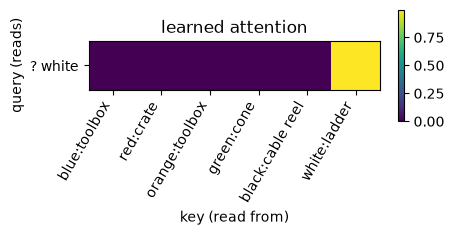

In [12]:
with torch.no_grad():
    c, o, qc, t, wch = make_batch(1, torch.Generator().manual_seed(5))
    model(c, o, qc)
labels = [f"{COLORS[a]}:{OBJECTS[b]}" for a, b in zip(c[0].tolist(), o[0].tolist())]
show(model.attn.last_weights[0, 0], labels, [f"? {COLORS[qc.item()]}"], "learned attention")

The query concentrates its weight on the pair whose colour matches: the network learned *what to look
for* ($W_Q$), *what to advertise* ($W_K$) and *what to return* ($W_V$). This is the mechanism by which an
action query in a VLA can find "the red toolbox" among image patches.

## Exercises
1. Remove the $1/\sqrt{d_k}$ scaling in `scaled_dot_product_attention` (copy it locally) and retrain
   the recall model with $d=256$. What happens to the training curve?
2. Make the recall task need *two* hops (each pair token is split into a colour token followed by an
   object token). Show one attention layer is not enough and two are (an induction-head-like circuit).
3. Implement grouped-query attention with $h=8$ query heads and $g=2$ K/V heads; verify it equals MHA
   when the K/V weights of heads in the same group are tied.
4. Write a prefix-LM mask for `[img×4][text×3][actions×3]` where actions see everything before them and
   each other bidirectionally (π0-style), and check with a gradient test that image tokens' outputs do
   not depend on action inputs.